In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/raunakkumarshs/soh-datatset/battery_cycle_level_dataset_CLEAN_FINAL.csv


[INFO] Loaded dataset: 1415 rows, 7 columns.
[INFO] Identified 34 unique batteries.
[INFO] Battery ID Col: 'battery_id' | Cycle Col: 'cycle' | Target Col: 'soh'
[INFO] Extracted 3 Health Indicator (HI) features: ['voltage', 'temperature', 'capacity']

--- Health Indicator (HI) Relevance Ranking (Saleh et al. & Liu et al.) ---
    Feature  GRA_Score  MI_Score  Pearson_r
   capacity     0.7767    2.1628     0.6435
    voltage     0.6700    0.9989     0.2575
temperature     0.6671    0.7666     0.4186

--- Training Model 1: Self-Adaptive Physics-Informed Attention-GRU (SA-PI-AGRU) ---
[SA-PI-AGRU] Epoch 001/150 | Data MSE: 0.119935 | Physics MSE: 0.001982 | Val RMSE: 13.289%
[SA-PI-AGRU] Epoch 025/150 | Data MSE: 0.003922 | Physics MSE: 0.000003 | Val RMSE: 8.933%
[SA-PI-AGRU] Epoch 050/150 | Data MSE: 0.001280 | Physics MSE: 0.000009 | Val RMSE: 10.380%
[SA-PI-AGRU] Epoch 075/150 | Data MSE: 0.000998 | Physics MSE: 0.000012 | Val RMSE: 13.829%
[SA-PI-AGRU] Epoch 100/150 | Data MSE: 0.000

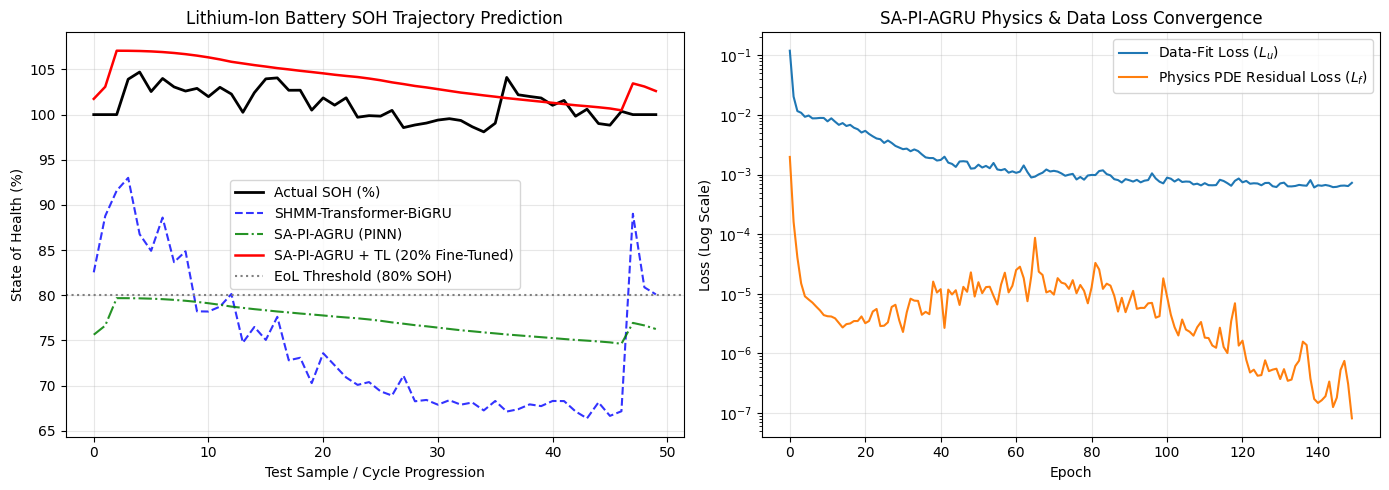

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis, skew, entropy

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import mutual_info_regression
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")

# Set random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =====================================================================
# 1. DATA LOADING, CLEANING & HEALTH INDICATOR (HI) ENGINEERING
#    Ref: Fu et al. (2026), Saleh et al. (2026), Liu et al. (2026)
# =====================================================================
def load_and_preprocess_dataset(csv_path="/kaggle/input/datasets/raunakkumarshs/soh-datatset/battery_cycle_level_dataset_CLEAN_FINAL.csv"):
    """
    Loads battery_cycle_level_dataset_CLEAN_FINAL.csv, automatically detects
    battery ID, cycle index, SOH/capacity targets, and extracts the 16+ statistical
    and waveform Health Indicators (HIs).
    """
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"Could not find '{csv_path}'. Check the Kaggle input directory path.")

    # Handle standard CSV or compressed archive if applicable
    try:
        df = pd.read_csv(csv_path)
    except Exception:
        df = pd.read_csv(csv_path, compression="infer", encoding_errors="ignore")

    print(f"[INFO] Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns.")
    cols_lower = {c.lower().strip(): c for c in df.columns}

    # 1. Detect Battery / Cell ID column
    id_candidates = ["battery_id", "cell_id", "battery", "cell", "id", "channel", "group"]
    id_col = next((cols_lower[k] for k in id_candidates if k in cols_lower), None)
    if id_col is None:
        # Check for string/categorical column
        obj_cols = df.select_dtypes(include=["object", "category"]).columns
        id_col = obj_cols[0] if len(obj_cols) > 0 else "Battery_ID"
        if id_col not in df.columns:
            df[id_col] = "Cell_01"

    # 2. Detect Cycle Index column (t)
    cycle_candidates = ["cycle", "cycle_index", "cycle_number", "cycles", "t"]
    cycle_col = next((cols_lower[k] for k in cycle_candidates if k in cols_lower), None)
    if cycle_col is None:
        df["cycle_index"] = df.groupby(id_col).cumcount() + 1
        cycle_col = "cycle_index"

    # 3. Detect or Compute SOH Target: SOH(k) = Q_max(k) / Q_ref (Eq. 1 in Lyu et al., Eq. 6 in Saleh et al.)
    soh_candidates = ["soh", "state_of_health", "soh_pct", "soh_value"]
    cap_candidates = ["discharge_capacity", "capacity", "q_discharge", "q_max", "cap"]
    soh_col = next((cols_lower[k] for k in soh_candidates if k in cols_lower), None)

    if soh_col is None:
        cap_col = next((cols_lower[k] for k in cap_candidates if k in cols_lower), None)
        if cap_col is None:
            raise ValueError("Dataset must contain an SOH or Capacity column.")
        # Normalize capacity per cell by its initial reference capacity Q_ref
        df["SOH"] = df.groupby(id_col)[cap_col].transform(lambda x: x / x.iloc[0])
        soh_col = "SOH"
    else:
        # Convert percentage SOH (e.g., 95.0) to [0, 1] scale if > 1.5, matching Saleh et al. (2026)
        if df[soh_col].max() > 1.5:
            df[soh_col] = df[soh_col] / 100.0

    # Sort chronologically per battery cell
    df = df.sort_values(by=[id_col, cycle_col]).reset_index(drop=True)

    # 4. Select Numeric Health Indicators (HIs)
    exclude_cols = {id_col, cycle_col, soh_col}
    # Also exclude raw target leakage columns if SOH was derived from discharge capacity
    for k in ["rul", "remaining_useful_life", "eol"]:
        if k in cols_lower:
            exclude_cols.add(cols_lower[k])

    feature_cols = [
        c for c in df.select_dtypes(include=[np.number]).columns
        if c not in exclude_cols
    ]

    # Clean missing or infinite values via linear interpolation per cell (Zhang et al., 2026)
    df[feature_cols] = df.groupby(id_col)[feature_cols].transform(
        lambda g: g.interpolate(method="linear", limit_direction="both")
    ).fillna(0.0)

    print(f"[INFO] Identified {df[id_col].nunique()} unique batteries.")
    print(f"[INFO] Battery ID Col: '{id_col}' | Cycle Col: '{cycle_col}' | Target Col: '{soh_col}'")
    print(f"[INFO] Extracted {len(feature_cols)} Health Indicator (HI) features: {feature_cols}")
    return df, id_col, cycle_col, soh_col, feature_cols


# =====================================================================
# 2. FEATURE CORRELATION: GREY RELATIONAL ANALYSIS (GRA) & MUTUAL INFO
#    Ref: Liu et al. (2026) Eq. (3) & Saleh et al. (2026) Fig. 3-4
# =====================================================================
def compute_gra_and_mi(df, feature_cols, soh_col, rho=0.5):
    """
    Computes Grey Relational Grade (GRA, Eq. 3 in Liu et al., 2026)
    and Mutual Information (MI, Saleh et al., 2026) between HIs and SOH.
    """
    scaler = MinMaxScaler()
    X_norm = scaler.fit_transform(df[feature_cols].values)
    y_norm = scaler.fit_transform(df[[soh_col]].values).ravel()

    # Grey Relational Analysis (GRA)
    abs_diff = np.abs(X_norm - y_norm[:, None])
    d_min, d_max = np.min(abs_diff), np.max(abs_diff)
    gra_matrix = (d_min + rho * d_max) / (abs_diff + rho * d_max + 1e-8)
    gra_scores = np.mean(gra_matrix, axis=0)

    # k-NN Mutual Information Score
    mi_scores = mutual_info_regression(X_norm, y_norm, random_state=SEED)
    pcc_scores = [np.corrcoef(X_norm[:, i], y_norm)[0, 1] for i in range(len(feature_cols))]

    ranking_df = pd.DataFrame({
        "Feature": feature_cols,
        "GRA_Score": np.round(gra_scores, 4),
        "MI_Score": np.round(mi_scores, 4),
        "Pearson_r": np.round(pcc_scores, 4)
    }).sort_values(by="MI_Score", ascending=False).reset_index(drop=True)

    print("\n--- Health Indicator (HI) Relevance Ranking (Saleh et al. & Liu et al.) ---")
    print(ranking_df.to_string(index=False))
    return ranking_df


# =====================================================================
# 3. SEGMENTED HIDDEN MARKOV MODEL (SHMM) STATE ENCODER
#    Ref: Liu et al. (2026) Section 3.2, Eqs. (4)-(8)
# =====================================================================
def append_shmm_latent_states(df, id_col, feature_cols, n_states=4, segment_len=5):
    """
    Approximates the Segmented Hidden Markov Model (SHMM) latent state abstraction
    (Liu et al., 2026) by clustering local temporal windows into discrete hidden states
    and computing the statistical mode across segments.
    """
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(df[feature_cols].values)

    # Fit global Gaussian state emission model across all cells
    kmeans_hmm = KMeans(n_clusters=n_states, random_state=SEED, n_init=10)
    raw_states = kmeans_hmm.fit_predict(X_scaled)
    df["SHMM_Raw_State"] = raw_states

    # Segment-level statistical mode encoding (Eq. 7 in Liu et al., 2026)
    def segment_mode(series, seg_len):
        vals = series.values
        out = np.zeros_like(vals)
        for i in range(0, len(vals), seg_len):
            chunk = vals[i:i + seg_len]
            counts = np.bincount(chunk)
            out[i:i + seg_len] = np.argmax(counts)
        return pd.Series(out, index=series.index)

    df["SHMM_Mode_State"] = df.groupby(id_col)["SHMM_Raw_State"].transform(
        lambda s: segment_mode(s, segment_len)
    )
    df.drop(columns=["SHMM_Raw_State"], inplace=True)
    updated_features = feature_cols + ["SHMM_Mode_State"]
    return df, updated_features


# =====================================================================
# 4. MODEL 1: SELF-ADAPTIVE PHYSICS-INFORMED ATTENTION-GRU (SA-PI-AGRU)
#    Ref: Saleh et al. (IEEE Trans. Transp. Electrif., Oct 2026)
#    Eqs. (4)-(17), Algorithm 1, Table II
# =====================================================================
class ScaledDotProductAttention(nn.Module):
    """Soft Attention Layer (Saleh et al., 2026, Eqs. 15-17)."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.query = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.key = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.scale = np.sqrt(hidden_dim)

    def forward(self, h_seq):
        # h_seq: (batch, seq_len, hidden_dim)
        q = self.query(h_seq)
        k = self.key(h_seq)
        scores = torch.bmm(q, k.transpose(1, 2)) / self.scale
        attn_weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(attn_weights, h_seq)
        # Return final attended context step
        return context[:, -1, :], attn_weights


class AGRUBranch(nn.Module):
    """
    3-Layer GRU with 32 neurons, GELU activation, 0.2 Dropout, and Soft Attention
    (Saleh et al., 2026, Table II & Fig. 2).
    """
    def __init__(self, input_dim, hidden_dim=32, num_layers=3, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.attention = ScaledDotProductAttention(hidden_dim)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x_seq):
        # Disable cuDNN RNN kernel only during second-order/AutoDiff graph creation if needed
        gru_out, _ = self.gru(x_seq)
        context, attn_weights = self.attention(gru_out)
        out = self.fc(context)
        return out, attn_weights


class SAPIAGRU(nn.Module):
    """
    Complete Self-Adaptive Physics-Informed Attention-GRU (Saleh et al., 2026).
    - Branch 1 (Phi): Maps (x, t) -> predicted SOH u_hat
    - AutoDiff: Computes exact partial derivatives du_hat/dt and du_hat/dx
    - Branch 2 (phi): Models latent PDE degradation operator F(x, t, u_hat, u_x, u_t; phi)
    - Self-Adaptive Loss Weights: Trainable log-variance parameters lambda'_u and lambda'_f
    """
    def __init__(self, num_hi_features, hidden_dim=32, num_layers=3, dropout=0.2):
        super().__init__()
        self.num_hi = num_hi_features
        # Surrogate SOH network u(x, t; Phi) -> takes S HIs + 1 cycle index t
        self.surrogate_net = AGRUBranch(num_hi_features + 1, hidden_dim, num_layers, dropout)

        # Deep Hidden Physics Operator F(x, t, u_hat, u_t, u_x; phi)
        # Input size = S HIs + 1 (t) + 1 (u_hat) + 1 (u_t) + S (u_x) = 2*S + 3
        physics_input_dim = 2 * num_hi_features + 3
        self.physics_net = AGRUBranch(physics_input_dim, hidden_dim, num_layers, dropout)

        # Self-adaptive trainable log-weights lambda'_u and lambda'_f (Eq. 10 in Saleh et al.)
        self.lambda_u_prime = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))
        self.lambda_f_prime = nn.Parameter(torch.tensor(0.0, dtype=torch.float32))

    def forward(self, x_seq, t_seq):
        """
        x_seq: (batch, seq_len, S) - Health Indicator sequence
        t_seq: (batch, seq_len, 1) - Normalized cycle index sequence
        """
        # Enable gradient tracking on inputs for AutoDiff PDE residual calculation
        if not x_seq.requires_grad:
            x_seq = x_seq.clone().detach().requires_grad_(True)
        if not t_seq.requires_grad:
            t_seq = t_seq.clone().detach().requires_grad_(True)

        surrogate_in = torch.cat([x_seq, t_seq], dim=-1)
        u_hat, attn_weights = self.surrogate_net(surrogate_in)

        # Compute exact first-order derivatives via AutoDiff (Algorithm 1, Line 7)
        ones = torch.ones_like(u_hat)
        u_t_seq = torch.autograd.grad(
            outputs=u_hat, inputs=t_seq, grad_outputs=ones,
            create_graph=True, retain_graph=True
        )[0]
        u_x_seq = torch.autograd.grad(
            outputs=u_hat, inputs=x_seq, grad_outputs=ones,
            create_graph=True, retain_graph=True
        )[0]

        # Broadcast scalar u_hat across sequence length to form tuple [x, t, u_hat, u_t, u_x]
        u_hat_expanded = u_hat.unsqueeze(1).expand(-1, x_seq.size(1), 1)
        physics_in = torch.cat([x_seq, t_seq, u_hat_expanded, u_t_seq, u_x_seq], dim=-1)

        F_pred, _ = self.physics_net(physics_in)
        # Physics PDE residual at the current cycle step: f = u_t - F (Eq. 5)
        u_t_last = u_t_seq[:, -1, :]
        f_residual = u_t_last - F_pred

        return u_hat, f_residual, attn_weights

    def compute_self_adaptive_loss(self, u_hat, u_true, f_residual):
        """
        Computes Eq. (10) from Saleh et al. (2026):
        L = exp(-lambda'_u)*L_u + exp(-lambda'_f)*L_f + lambda'_u + lambda'_f
        """
        L_u = torch.mean((u_hat - u_true) ** 2)
        L_f = torch.mean(f_residual ** 2)
        total_loss = (
            torch.exp(-self.lambda_u_prime) * L_u
            + torch.exp(-self.lambda_f_prime) * L_f
            + self.lambda_u_prime
            + self.lambda_f_prime
        )
        return total_loss, L_u.item(), L_f.item()


# =====================================================================
# 5. MODEL 2: SHMM-TRANSFORMER-BiGRU HYBRID NETWORK
#    Ref: Liu et al. (Measurement 257, 2026) Section 3.1-3.4, Fig. 6
# =====================================================================
class SHMMTransformerBiGRU(nn.Module):
    """
    Hybrid SHMM-Transformer-BiGRU Network (Liu et al., 2026).
    Integrates Multi-Head Self-Attention Transformer with Bidirectional GRU.
    """
    def __init__(self, input_dim, d_model=32, nhead=4, hidden_dim=32, num_layers=2, dropout=0.2):
        super().__init__()
        self.input_proj = nn.Linear(input_dim + 1, d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.bigru = nn.GRU(
            input_size=d_model,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x_seq, t_seq):
        inp = torch.cat([x_seq, t_seq], dim=-1)
        proj = self.input_proj(inp)
        trans_out = self.transformer(proj)
        bigru_out, _ = self.bigru(trans_out)
        out = self.fc(bigru_out[:, -1, :])
        return out


# =====================================================================
# 6. SEQUENCE DATASET BUILDER & STRATEGY 2 SPLIT (70% / 15% / 15%)
#    Ref: Fu et al. (2026) Section 3.3 & Saleh et al. (2026) Section III-B
# =====================================================================
class BatterySequenceDataset(Dataset):
    def __init__(self, X_seqs, t_seqs, y_targets):
        self.X = torch.tensor(X_seqs, dtype=torch.float32)
        self.t = torch.tensor(t_seqs, dtype=torch.float32)
        self.y = torch.tensor(y_targets, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.t[idx], self.y[idx]


def build_sequences_per_cell(df, id_col, cycle_col, soh_col, feature_cols, seq_len=10):
    """Creates sliding window sequences per battery cell without cross-cell leakage."""
    X_list, t_list, y_list, cell_ids = [], [], [], []
    for cell_id, group in df.groupby(id_col):
        X_cell = group[feature_cols].values
        t_cell = group[[cycle_col]].values
        y_cell = group[[soh_col]].values

        for i in range(len(group)):
            start_idx = max(0, i - seq_len + 1)
            x_win = X_cell[start_idx:i + 1]
            t_win = t_cell[start_idx:i + 1]
            # Pad early cycles with initial cycle state
            if len(x_win) < seq_len:
                pad_len = seq_len - len(x_win)
                x_win = np.vstack([np.repeat(x_win[0:1], pad_len, axis=0), x_win])
                t_win = np.vstack([np.repeat(t_win[0:1], pad_len, axis=0), t_win])

            X_list.append(x_win)
            t_list.append(t_win)
            y_list.append(y_cell[i])
            cell_ids.append(cell_id)

    return np.array(X_list), np.array(t_list), np.array(y_list), np.array(cell_ids)


# =====================================================================
# 7. TRAINING, EVALUATION & TRANSFER LEARNING (TL) PIPELINE
#    Ref: Saleh et al. (2026) Alg. 1 & Zhang et al. (2026) Section 3.4
# =====================================================================
def evaluate_predictions(y_true, y_pred, eol_threshold=0.80):
    """Calculates RMSE (%), MAE (%), MAPE (%), R2 (%), and EoL Cycle Error."""
    y_true = y_true.ravel()
    y_pred = y_pred.ravel()
    rmse = np.sqrt(mean_squared_error(y_true, y_pred)) * 100.0
    mae = mean_absolute_error(y_true, y_pred) * 100.0
    mape = np.mean(np.abs((y_true - y_pred) / np.clip(y_true, 1e-5, None))) * 100.0
    r2 = r2_score(y_true, y_pred) * 100.0

    # EoL Cycle Error E (Table V in Saleh et al., 2026)
    true_eol = np.where(y_true <= eol_threshold)[0]
    pred_eol = np.where(y_pred <= eol_threshold)[0]
    if len(true_eol) > 0 and len(pred_eol) > 0:
        eol_err = int(pred_eol[0] - true_eol[0])
    else:
        eol_err = 0
    return {"RMSE (%)": rmse, "MAE (%)": mae, "MAPE (%)": mape, "R2 (%)": r2, "EoL_Error (cycles)": eol_err}


def train_sapi_agru(model, train_loader, val_loader, epochs=150, lr=0.005):
    """Trains the SA-PI-AGRU model using Adam and Self-Adaptive PINN loss."""
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"data_loss": [], "physics_loss": [], "lambda_u": [], "lambda_f": []}

    best_val_loss = float("inf")
    best_weights = None

    for epoch in range(1, epochs + 1):
        model.train()
        ep_data_loss, ep_phys_loss = 0.0, 0.0
        for X_b, t_b, y_b in train_loader:
            X_b, t_b, y_b = X_b.to(DEVICE), t_b.to(DEVICE), y_b.to(DEVICE)
            optimizer.zero_grad()
            u_hat, f_res, _ = model(X_b, t_b)
            loss, l_u, l_f = model.compute_self_adaptive_loss(u_hat, y_b, f_res)
            loss.backward()
            optimizer.step()
            ep_data_loss += l_u
            ep_phys_loss += l_f

        n_batches = max(1, len(train_loader))
        history["data_loss"].append(ep_data_loss / n_batches)
        history["physics_loss"].append(ep_phys_loss / n_batches)
        history["lambda_u"].append(torch.exp(-model.lambda_u_prime).item())
        history["lambda_f"].append(torch.exp(-model.lambda_f_prime).item())

        # Validation step
        model.eval()
        val_mse = 0.0
        for X_v, t_v, y_v in val_loader:
            X_v, t_v, y_v = X_v.to(DEVICE), t_v.to(DEVICE), y_v.to(DEVICE)
            u_hat_v, _, _ = model(X_v, t_v)
            val_mse += torch.mean((u_hat_v.detach() - y_v) ** 2).item()
        val_mse /= max(1, len(val_loader))

        if val_mse < best_val_loss:
            best_val_loss = val_mse
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if epoch % 25 == 0 or epoch == 1:
            print(f"[SA-PI-AGRU] Epoch {epoch:03d}/{epochs:03d} | "
                  f"Data MSE: {history['data_loss'][-1]:.6f} | "
                  f"Physics MSE: {history['physics_loss'][-1]:.6f} | "
                  f"Val RMSE: {np.sqrt(val_mse)*100:.3f}%")

    if best_weights is not None:
        model.load_state_dict({k: v.to(DEVICE) for k, v in best_weights.items()})
    return model, history


def fine_tune_transfer_learning(pretrained_model, X_target, t_target, y_target, finetune_ratio=0.20, epochs=40, lr=0.0005):
    """
    Implements Transfer Learning (Zhang et al., 2026 Section 3.4 & Fu et al., 2026 Section 5.1.2):
    Freezes GRU/Attention layers and fine-tunes ONLY the Fully Connected Layers (FCL)
    using the first 20% of cycles from the target test battery.
    """
    import copy
    tl_model = copy.deepcopy(pretrained_model).to(DEVICE)

    # Freeze GRU and Attention layers in Surrogate Net
    for name, param in tl_model.named_parameters():
        if "surrogate_net.fc" in name:
            param.requires_grad = True
        else:
            param.requires_grad = False

    n_finetune = max(5, int(len(y_target) * finetune_ratio))
    X_ft = torch.tensor(X_target[:n_finetune], dtype=torch.float32).to(DEVICE)
    t_ft = torch.tensor(t_target[:n_finetune], dtype=torch.float32).to(DEVICE)
    y_ft = torch.tensor(y_target[:n_finetune], dtype=torch.float32).to(DEVICE)

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, tl_model.parameters()), lr=lr)
    criterion = nn.MSELoss()

    tl_model.train()
    for _ in range(epochs):
        optimizer.zero_grad()
        surrogate_in = torch.cat([X_ft, t_ft], dim=-1)
        u_hat, _ = tl_model.surrogate_net(surrogate_in)
        loss = criterion(u_hat, y_ft)
        loss.backward()
        optimizer.step()

    tl_model.eval()
    with torch.no_grad():
        X_all = torch.tensor(X_target, dtype=torch.float32).to(DEVICE)
        t_all = torch.tensor(t_target, dtype=torch.float32).to(DEVICE)
        surrogate_in_all = torch.cat([X_all, t_all], dim=-1)
        preds_tl, _ = tl_model.surrogate_net(surrogate_in_all)

    return preds_tl.cpu().numpy()


# =====================================================================
# 8. MAIN EXECUTION WORKFLOW
# =====================================================================
if __name__ == "__main__":
    CSV_FILE = "/kaggle/input/datasets/raunakkumarshs/soh-datatset/battery_cycle_level_dataset_CLEAN_FINAL.csv"

    # Step 1: Load dataset & extract Health Indicators
    df, id_col, cycle_col, soh_col, feature_cols = load_and_preprocess_dataset(CSV_FILE)

    # Step 2: Run GRA & Mutual Information Feature Analysis
    ranking_df = compute_gra_and_mi(df, feature_cols, soh_col)

    # Step 3: Append SHMM Latent State Feature (Liu et al., 2026)
    df, feature_cols = append_shmm_latent_states(df, id_col, feature_cols, n_states=4, segment_len=5)

    # Step 4: Normalize HIs & Cycle Index (Min-Max Scaling, Eq. 16 in Liu et al., Eq. 7 in Zhang et al.)
    feat_scaler = MinMaxScaler()
    t_scaler = MinMaxScaler()
    df[feature_cols] = feat_scaler.fit_transform(df[feature_cols].values)
    df["t_norm"] = t_scaler.fit_transform(df[[cycle_col]].values)

    # Step 5: Build Temporal Sequences (Sequence Length = 10 cycles)
    SEQ_LEN = 10
    X_seqs, t_seqs, y_targets, cell_ids = build_sequences_per_cell(
        df, id_col, "t_norm", soh_col, feature_cols, seq_len=SEQ_LEN
    )

    # Step 6: Split Data (Strategy 2: 70% Train Cells, 15% Val Cells, 15% Test Cells - Saleh et al., 2026)
    unique_cells = df[id_col].unique()
    if len(unique_cells) >= 5:
        n_train = max(1, int(0.70 * len(unique_cells)))
        n_val = max(1, int(0.15 * len(unique_cells)))
        train_cells = unique_cells[:n_train]
        val_cells = unique_cells[n_train:n_train + n_val]
        test_cells = unique_cells[n_train + n_val:]
        if len(test_cells) == 0:
            test_cells = val_cells

        train_mask = np.isin(cell_ids, train_cells)
        val_mask = np.isin(cell_ids, val_cells)
        test_mask = np.isin(cell_ids, test_cells)
    else:
        # Fallback to Strategy 1 (chronological split) if fewer than 5 batteries exist
        n_total = len(y_targets)
        idx = np.arange(n_total)
        train_mask = idx < int(0.70 * n_total)
        val_mask = (idx >= int(0.70 * n_total)) & (idx < int(0.85 * n_total))
        test_mask = idx >= int(0.85 * n_total)
        test_cells = unique_cells

    train_loader = DataLoader(
        BatterySequenceDataset(X_seqs[train_mask], t_seqs[train_mask], y_targets[train_mask]),
        batch_size=64, shuffle=True
    )
    val_loader = DataLoader(
        BatterySequenceDataset(X_seqs[val_mask], t_seqs[val_mask], y_targets[val_mask]),
        batch_size=64, shuffle=False
    )

    # Step 7: Train Primary Model (SA-PI-AGRU - Saleh et al., 2026)
    print("\n--- Training Model 1: Self-Adaptive Physics-Informed Attention-GRU (SA-PI-AGRU) ---")
    sapi_agru = SAPIAGRU(num_hi_features=len(feature_cols), hidden_dim=32, num_layers=3, dropout=0.2)
    sapi_agru, pinn_history = train_sapi_agru(sapi_agru, train_loader, val_loader, epochs=150, lr=0.005)

    # Step 8: Train Benchmark Hybrid Model (SHMM-Transformer-BiGRU - Liu et al., 2026)
    print("\n--- Training Model 2: SHMM-Transformer-BiGRU Hybrid Network ---")
    trans_bigru = SHMMTransformerBiGRU(input_dim=len(feature_cols), d_model=32, nhead=4, hidden_dim=32).to(DEVICE)
    opt_tb = torch.optim.Adam(trans_bigru.parameters(), lr=0.003)
    loss_fn = nn.MSELoss()
    for ep in range(1, 101):
        trans_bigru.train()
        for X_b, t_b, y_b in train_loader:
            X_b, t_b, y_b = X_b.to(DEVICE), t_b.to(DEVICE), y_b.to(DEVICE)
            opt_tb.zero_grad()
            pred = trans_bigru(X_b, t_b)
            l = loss_fn(pred, y_b)
            l.backward()
            opt_tb.step()

    # Step 9: Evaluate on Test Set & Perform 20% Transfer Learning Fine-Tuning (Zhang et al., 2026)
    X_test, t_test, y_test = X_seqs[test_mask], t_seqs[test_mask], y_targets[test_mask]

    sapi_agru.eval()
    X_t_tensor = torch.tensor(X_test, dtype=torch.float32).to(DEVICE)
    t_t_tensor = torch.tensor(t_test, dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        preds_sapi, _ = sapi_agru.surrogate_net(torch.cat([X_t_tensor, t_t_tensor], dim=-1))
        preds_sapi = preds_sapi.cpu().numpy()
        preds_tbigru = trans_bigru(X_t_tensor, t_t_tensor).cpu().numpy()

    # Transfer Learning Fine-Tuning on the first 20% of target test data
    preds_sapi_tl = fine_tune_transfer_learning(sapi_agru, X_test, t_test, y_test, finetune_ratio=0.20)

    metrics_sapi = evaluate_predictions(y_test, preds_sapi)
    metrics_tbigru = evaluate_predictions(y_test, preds_tbigru)
    metrics_tl = evaluate_predictions(y_test, preds_sapi_tl)

    results_table = pd.DataFrame([
        {"Model": "SHMM-Transformer-BiGRU (Liu et al., 2026)", **metrics_tbigru},
        {"Model": "SA-PI-AGRU [PINN] (Saleh et al., 2026)", **metrics_sapi},
        {"Model": "SA-PI-AGRU + Transfer Learning (Zhang et al., 2026)", **metrics_tl},
    ])
    print("\n================ FINAL SOH ESTIMATION PERFORMANCE ================")
    print(results_table.to_string(index=False))

    # Step 10: Plot Degradation Trajectory & Self-Adaptive Loss Convergence
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(y_test * 100, "k-", lw=2, label="Actual SOH (%)")
    axes[0].plot(preds_tbigru * 100, "b--", alpha=0.8, label="SHMM-Transformer-BiGRU")
    axes[0].plot(preds_sapi * 100, "g-.", alpha=0.85, label="SA-PI-AGRU (PINN)")
    axes[0].plot(preds_sapi_tl * 100, "r-", lw=1.8, label="SA-PI-AGRU + TL (20% Fine-Tuned)")
    axes[0].axhline(80.0, color="gray", linestyle=":", label="EoL Threshold (80% SOH)")
    axes[0].set_title("Lithium-Ion Battery SOH Trajectory Prediction")
    axes[0].set_xlabel("Test Sample / Cycle Progression")
    axes[0].set_ylabel("State of Health (%)")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].semilogy(pinn_history["data_loss"], label="Data-Fit Loss ($L_u$)")
    axes[1].semilogy(pinn_history["physics_loss"], label="Physics PDE Residual Loss ($L_f$)")
    axes[1].set_title("SA-PI-AGRU Physics & Data Loss Convergence")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss (Log Scale)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("SOH_Model_Evaluation_Results.png", dpi=300)
    print("\n[INFO] Saved evaluation plot to 'SOH_Model_Evaluation_Results.png'.")